# TCN Adding Problem: Colab reproduction

Run code cells in order on a CUDA GPU runtime. This notebook contains saved results from a single L4 run per configuration on 2026-11-10. Re-execution replaces outputs; numerical agreement is not guaranteed.

Upstream: https://github.com/locuslab/TCN (MIT), commit `2f8c2b817050206397458dfd1f5a25ce8a32fe65`.

Publication edits: pin upstream checkout; carry generated log paths into backup/plot cells; raise on training-process failure; remove transient download UI outputs. Training settings and saved experimental metrics are unchanged. The publication edits have not been rerun on Colab. Archived logs are in this repository's `logs/` folder. No trained checkpoints are included.


In [1]:
import sys
import torch

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA 사용 가능:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU가 연결되지 않았습니다. 런타임 설정을 확인하세요.")

Python: 3.13.16
PyTorch: 2.14.1+cu130
CUDA 사용 가능: True
GPU: NVIDIA L4


In [ ]:
from pathlib import Path
import subprocess
import os
import sys

repo_dir = Path("/content/TCN")
commit = "2f8c2b817050206397458dfd1f5a25ce8a32fe65"
if not repo_dir.exists():
    subprocess.run(["git", "clone", "https://github.com/locuslab/TCN.git", str(repo_dir)], check=True)
subprocess.run(["git", "checkout", "--detach", commit], cwd=repo_dir, check=True)
os.chdir(repo_dir)
if str(repo_dir) not in sys.path:
    sys.path.insert(0, str(repo_dir))
print("Working directory:", Path.cwd())
subprocess.run(["git", "rev-parse", "HEAD"], check=True)


In [3]:
import torch
from TCN.adding_problem.model import TCN

# 원본 Adding Problem 기본 구조
model = TCN(
    input_size=2,
    output_size=1,
    num_channels=[30] * 8,
    kernel_size=7,
    dropout=0.0,
).to("cuda")

# 샘플 4개, 각 시점의 값 2개, 시퀀스 길이 400
x = torch.randn(4, 2, 400, device="cuda")

model.eval()
with torch.no_grad():
    y = model(x)

print("입력 모양:", tuple(x.shape))
print("출력 모양:", tuple(y.shape))
print("모델 위치:", next(model.parameters()).device)
print("출력 위치:", y.device)
print("출력에 NaN·무한대 없음:", torch.isfinite(y).all().item())

/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


입력 모양: (4, 2, 400)
출력 모양: (4, 1)
모델 위치: cuda:0
출력 위치: cuda:0
출력에 NaN·무한대 없음: True


In [4]:
import subprocess
import sys
from pathlib import Path
from datetime import datetime

log_dir = Path("/content/TCN/reproduction_logs")
log_dir.mkdir(exist_ok=True)
log_path = log_dir / f"adding_T200_{datetime.now():%Y%m%d_%H%M%S}.log"

# 원본은 NumPy 시드를 설정하지 않으므로 실행 전에 추가
runner = """
import numpy as np
import runpy
import sys

np.random.seed(1111)
sys.argv = [
    "add_test",
    "--seq_len", "200",
    "--levels", "7",
    "--epochs", "3",
    "--seed", "1111",
]
runpy.run_module("TCN.adding_problem.add_test", run_name="__main__")
"""

print("로그 저장 위치:", log_path)

with log_path.open("w") as log_file:
    process = subprocess.Popen(
        [sys.executable, "-u", "-c", runner],
        cwd="/content/TCN",
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
    )
    for line in process.stdout:
        print(line, end="", flush=True)
        log_file.write(line)
        log_file.flush()

    return_code = process.wait()

print("\n종료 코드:", return_code)
print("로그 파일:", log_path)
t200_log_path = log_path
if return_code != 0:
    raise RuntimeError(f"Training failed; inspect {log_path}")


로그 저장 위치: /content/TCN/reproduction_logs/adding_T200_20261110_075016.log
Namespace(batch_size=32, cuda=True, dropout=0.0, clip=-1, epochs=3, ksize=7, levels=7, seq_len=200, log_interval=100, lr=0.004, optim='Adam', nhid=30, seed=1111)
Producing data...
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Train Epoch:  1 [  3168/ 50000 (6%)]	Learning rate: 0.0040	Loss: 0.240956
Train Epoch:  1 [  6368/ 50000 (13%)]	Learning rate: 0.0040	Loss: 0.164279
Train Epoch:  1 [  9568/ 50000 (19%)]	Learning rate: 0.0040	Loss: 0.171493
Train Epoch:  1 [ 12768/ 50000 (26%)]	Learning rate: 0.0040	Loss: 0.170041
Train Epoch:  1 [ 15968/ 50000 (32%)]	Learning rate: 0.0040	Loss: 0.169417
Train Epoch:  1 [ 19168/ 50000 (38%)]	Learning rate: 0.0040	Loss: 0.169233
Train Epoch:  1 [ 22368/ 50000 (45%)]	Learning rate: 0.0040	Loss: 0.

In [5]:
import subprocess
import sys
import time
from pathlib import Path
from datetime import datetime

log_dir = Path("/content/TCN/reproduction_logs")
log_dir.mkdir(exist_ok=True)
log_path = log_dir / f"adding_T400_{datetime.now():%Y%m%d_%H%M%S}.log"

runner = """
import numpy as np
import runpy
import sys

np.random.seed(1111)
sys.argv = [
    "add_test",
    "--seq_len", "400",
    "--levels", "8",
    "--epochs", "3",
    "--seed", "1111",
]
runpy.run_module("TCN.adding_problem.add_test", run_name="__main__")
"""

print("로그 저장 위치:", log_path)
started = time.perf_counter()

with log_path.open("w") as log_file:
    process = subprocess.Popen(
        [sys.executable, "-u", "-c", runner],
        cwd="/content/TCN",
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
    )

    for line in process.stdout:
        print(line, end="", flush=True)
        log_file.write(line)
        log_file.flush()

    return_code = process.wait()
    elapsed = time.perf_counter() - started

    summary = (
        f"\n종료 코드: {return_code}\n"
        f"전체 실행 시간: {elapsed:.1f}초\n"
    )
    print(summary)
    log_file.write(summary)

print("로그 파일:", log_path)
t400_log_path = log_path
if return_code != 0:
    raise RuntimeError(f"Training failed; inspect {log_path}")


로그 저장 위치: /content/TCN/reproduction_logs/adding_T400_20261110_075714.log
Namespace(batch_size=32, cuda=True, dropout=0.0, clip=-1, epochs=3, ksize=7, levels=8, seq_len=400, log_interval=100, lr=0.004, optim='Adam', nhid=30, seed=1111)
Producing data...
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)
Train Epoch:  1 [  3168/ 50000 (6%)]	Learning rate: 0.0040	Loss: 0.339744
Train Epoch:  1 [  6368/ 50000 (13%)]	Learning rate: 0.0040	Loss: 0.166161
Train Epoch:  1 [  9568/ 50000 (19%)]	Learning rate: 0.0040	Loss: 0.165545
Train Epoch:  1 [ 12768/ 50000 (26%)]	Learning rate: 0.0040	Loss: 0.173474
Train Epoch:  1 [ 15968/ 50000 (32%)]	Learning rate: 0.0040	Loss: 0.169182
Train Epoch:  1 [ 19168/ 50000 (38%)]	Learning rate: 0.0040	Loss: 0.168962
Train Epoch:  1 [ 22368/ 50000 (45%)]	Learning rate: 0.0040	Loss: 0.

In [ ]:
from pathlib import Path
from zipfile import ZipFile
from google.colab import files

log_paths = [t200_log_path, t400_log_path]
for path in log_paths:
    if not path.is_file():
        raise FileNotFoundError(path)
    print(f"Confirmed: {path.name} ({path.stat().st_size:,} bytes)")
zip_path = Path("/content/TCN_Adding_Problem_logs.zip")
with ZipFile(zip_path, "w") as archive:
    for path in log_paths:
        archive.write(path, arcname=path.name)
files.download(str(zip_path))


T=200, 7 blocks → Test MSE: [0.001812, 0.000285, 0.000531]
T=400, 8 blocks → Test MSE: [0.166145, 0.001375, 0.002161]


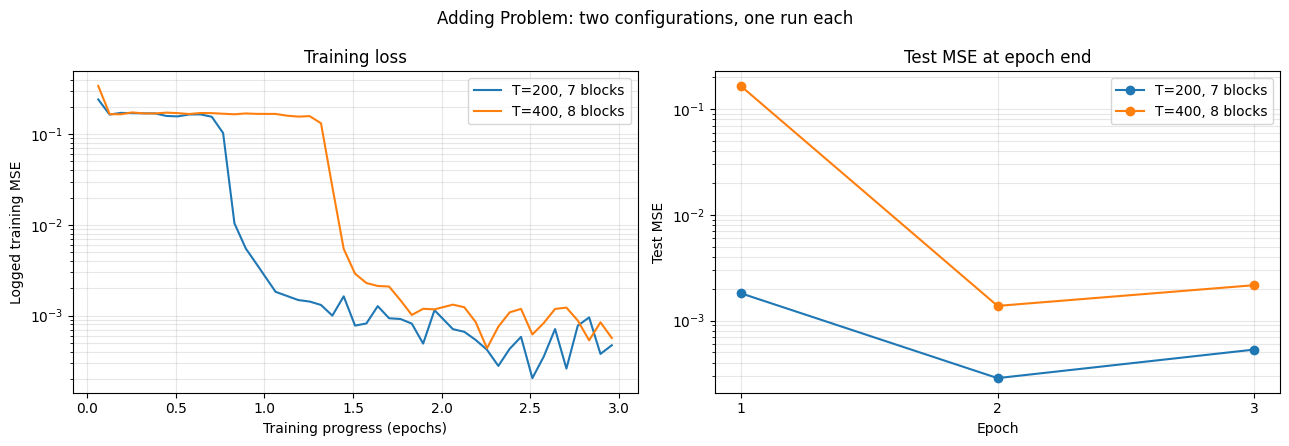

그래프 저장 위치: /content/TCN/reproduction_logs/adding_T200_T400_comparison.png


In [7]:
import re
from pathlib import Path
import matplotlib.pyplot as plt

log_dir = Path("/content/TCN/reproduction_logs")
experiments = {
    "T=200, 7 blocks": t200_log_path,
    "T=400, 8 blocks": t400_log_path,
}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for label, path in experiments.items():
    text = path.read_text()

    # 학습 로그에서 에폭, 처리한 샘플 수, 손실 추출
    records = re.findall(
        r"Train Epoch:\s*(\d+)\s*\[\s*(\d+)/\s*(\d+)"
        r"\s*\(\d+%\)\].*?Loss:\s*([0-9.eE+-]+)",
        text,
    )

    # 예: 1에폭의 50% → 가로축 0.5
    progress = [
        int(epoch) - 1 + int(done) / int(total)
        for epoch, done, total, loss in records
    ]
    train_loss = [float(loss) for _, _, _, loss in records]

    test_mse = [
        float(value)
        for value in re.findall(
            r"Test set: Average loss:\s*([0-9.eE+-]+)", text
        )
    ]

    if not records or len(test_mse) != 3:
        raise ValueError(f"로그 내용을 확인하세요: {path.name}")

    axes[0].plot(progress, train_loss, label=label)
    axes[1].plot([1, 2, 3], test_mse, marker="o", label=label)

    print(label, "→ Test MSE:", test_mse)

axes[0].set_title("Training loss")
axes[0].set_xlabel("Training progress (epochs)")
axes[0].set_ylabel("Logged training MSE")

axes[1].set_title("Test MSE at epoch end")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Test MSE")
axes[1].set_xticks([1, 2, 3])

for ax in axes:
    ax.set_yscale("log")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()

fig.suptitle("Adding Problem: two configurations, one run each")
fig.tight_layout()

figure_path = log_dir / "adding_T200_T400_comparison.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()

print("그래프 저장 위치:", figure_path)

In [ ]:
from google.colab import files

files.download(
    "/content/TCN/reproduction_logs/adding_T200_T400_comparison.png"
)